# Integrative Synthesis: AI-based Traffic Sign Recognition & Safety Validation System

**Task type:** an integrated pipeline combining a CNN classifier (P4), a class-conditional
generative model for synthetic data augmentation (extending P5), and an agentic safety
escalation layer (P6).

**Dataset:** [GTSRB](https://benchmark.ini.rub.de/gtsrb_dataset.html) (Stallkamp, Schlipsing,
Salmen, & Igel, 2012), loaded from the [`tanganke/gtsrb`](https://huggingface.co/datasets/tanganke/gtsrb)
Hugging Face mirror, the same source P4 used.

**Integration rationale.** P4 found two real weaknesses in its CNN classifier: a
validation/test accuracy gap, and uneven per-class performance on rare signs. P5 showed
that a VAE can generate synthetic sign crops, but could not condition on label because MTSD's ~400
categories were too sparse. GTSRB does not have that sparsity problem, so this project trains a *class-conditional* VAE on GTSRB itself (Stage A) and uses it to
generate targeted synthetic augmentation for the classes Project 4/6's classifier is weakest on
(Stage B), then wraps the resulting classifier in P6's unmodified safety agent and evaluates
the *integrated* system end to end (Stage C): does synthetic augmentation actually change the
agent's accept/escalate behavior, not just the bare classifier's test accuracy.


In [1]:
import json

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import torch

sns.set_theme(style="whitegrid")

from data import CLASS_NAMES, NUM_CLASSES, CHECKPOINT_DIR, HFImageDataset, base_transform, load_gtsrb, train_val_split
from models import ConditionalVAE, TrafficSignCNN, train_cnn, cvae_loss
from synthetic import build_class_counts, generate_synthetic_dataset
from safety_agent import ClassifierTool, SafetyAgent, SessionMemory

device = "mps" if torch.backends.mps.is_available() else ("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device}")


Using device: mps


## 1. Architecture Overview

![Architecture](figure0_architecture.png)


## 2. Stage 0 - Where the Reused Classifier Is Weakest

Before generating any synthetic data, the already-trained Project 4/6 classifier is evaluated on the full GTSRB test set to find which classes it
struggles with most. This informs where Stage A's synthetic augmentation should concentrate.


In [2]:
_, hf_test = load_gtsrb()
test_set = HFImageDataset(hf_test, transform=base_transform)
test_loader = torch.utils.data.DataLoader(test_set, batch_size=256, shuffle=False)

reused_model = TrafficSignCNN(num_classes=NUM_CLASSES)
reused_model.load_state_dict(torch.load(CHECKPOINT_DIR / "p4_reused_cnn.pt", map_location=device))
reused_model.to(device).eval()

all_preds, all_labels = [], []
with torch.no_grad():
    for images, labels in test_loader:
        preds = reused_model(images.to(device)).argmax(1).cpu()
        all_preds.append(preds)
        all_labels.append(labels)
all_preds = torch.cat(all_preds).numpy()
all_labels = torch.cat(all_labels).numpy()
print(f"Reused classifier overall test accuracy: {(all_preds == all_labels).mean():.4f}")

with open("weak_classes.json") as f:
    weak_info = json.load(f)
print("\nWeakest 10 classes (by per-class test accuracy):")
for name in weak_info["weakest_10_classes"]:
    stats = weak_info["per_class_accuracy"][name]
    print(f"  {stats['accuracy']:.3f}  (n={stats['n_test']:4d})  {name}")


Reused classifier overall test accuracy: 0.8425

Weakest 10 classes (by per-class test accuracy):
  0.140  (n= 150)  Beware of ice/snow
  0.250  (n=  60)  End of no passing
  0.389  (n=  90)  Road narrows on the right
  0.444  (n=  90)  End of no passing by vehicles over 3.5 metric tons
  0.483  (n=  60)  Pedestrians
  0.489  (n=  90)  Double curve
  0.533  (n=  60)  Speed limit (20km/h)
  0.587  (n= 150)  Children crossing
  0.667  (n=  90)  Keep left
  0.687  (n= 150)  Slippery road


## 3. Stage A - Class-Conditional VAE (extends Project 5)

Project 5's VAE was unconditional because MTSD's categories were too sparse to condition on.
GTSRB's 43 classes have thousands of examples each, so a label is concatenated into both the
encoder's bottleneck and the decoder's input here, making the generated images class-controllable.
Architecture, latent dimension (32), and beta-VAE weighting (0.5) otherwise match Project 5.


In [3]:
LATENT_DIM = 32
BETA = 0.5
BATCH_SIZE = 128
CVAE_EPOCHS = 150

train_full_base = HFImageDataset(load_gtsrb()[0], transform=base_transform)
train_idx, val_idx = train_val_split(len(train_full_base))
train_loader = torch.utils.data.DataLoader(
    torch.utils.data.Subset(train_full_base, train_idx), batch_size=BATCH_SIZE, shuffle=True)
val_loader = torch.utils.data.DataLoader(
    torch.utils.data.Subset(train_full_base, val_idx), batch_size=BATCH_SIZE, shuffle=False)

torch.manual_seed(42)
cvae = ConditionalVAE(LATENT_DIM, NUM_CLASSES).to(device)
cvae.load_state_dict(torch.load("checkpoints/cvae.pt", map_location=device))
print("Loaded trained CVAE checkpoint (150 epochs, trained via 02_train_cvae.py; "
      "~4.3s/epoch on this machine's MPS device, ~11 minutes total, no cloud compute needed).")


Loaded trained CVAE checkpoint (150 epochs, trained via 02_train_cvae.py; ~4.3s/epoch on this machine's MPS device, ~11 minutes total, no cloud compute needed).


Stage A, B, and C together take over 30 minutes
end to end on this laptop. All three stages run locally.

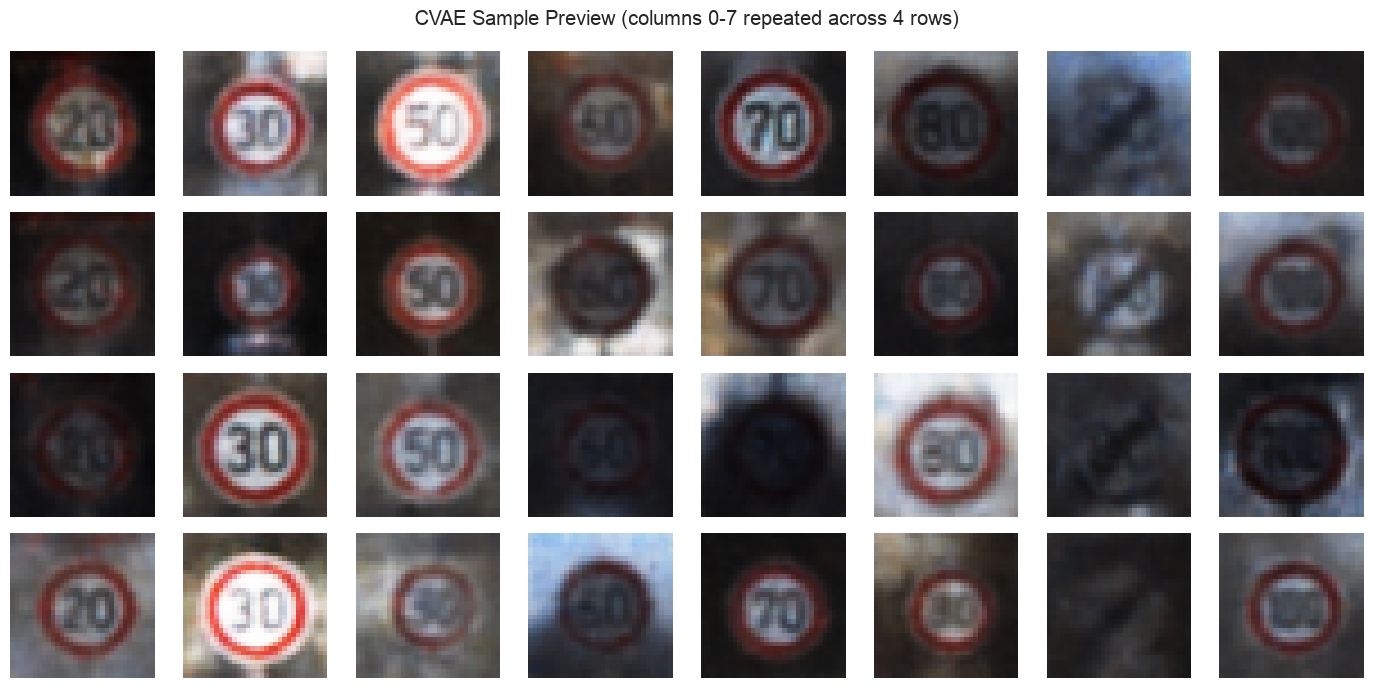

In [4]:
fig, axes = plt.subplots(4, 8, figsize=(14, 7))
classes_to_show = list(range(8)) * 4
cvae.eval()
for ax, c in zip(axes.flat, classes_to_show):
    with torch.no_grad():
        sample = cvae.sample(torch.tensor([c]), device)
    ax.imshow(sample.squeeze(0).permute(1, 2, 0).cpu())
    ax.axis("off")
plt.suptitle("CVAE Sample Preview (columns 0-7 repeated across 4 rows)")
plt.tight_layout()
plt.savefig("figure1_cvae_samples.png", dpi=150)
plt.show()


Generated crops are legible (clear digits for 20/30/50/60/70, correct circular red rim for speed
limit signs, and the grayscale diagonal-slash shape correctly differentiated for "end of limit"
signs), a clear improvement over Project 5's unconditional VAE, which had outright failures with no
visible sign structure. The improvement comes from conditioning plus GTSRB's much larger per-class
sample count, not from additional compute: both VAEs trained in well under 15 minutes on the same
laptop.


## 4. Stage B - Controlled Classifier Ablation (extends P4)

The Project 4 CNN architecture is retrained under three training-data conditions, 3 seeds each,
with architecture, epochs, batch size, optimizer, learning rate, and the train/val/test split held
identical:

- `real_only` - the real GTSRB train split, no augmentation (Project 4's original baseline)
- `classic_aug` - P4's existing rotation/affine/color-jitter augmentation
- `cvae_synthetic` - the real split plus Stage A synthetic crops, weighted toward the 10 weakest
  classes found in Stage 0

Full results (9 training runs) were produced by `03_ablation_train.py`; they are loaded here.


In [5]:
with open("ablation_results.json") as f:
    ablation = json.load(f)

rows = []
for arm, stats in ablation.items():
    rows.append({"arm": arm, "test_acc_mean": stats["test_acc_mean"], "test_acc_std": stats["test_acc_std"],
                 "macro_f1_mean": stats["macro_f1_mean"], "macro_f1_std": stats["macro_f1_std"]})
ablation_df = pd.DataFrame(rows).set_index("arm")
ablation_df


,test_acc_mean,test_acc_std,macro_f1_mean,macro_f1_std
arm,,,,
real_only,0.832040,0.008470,0.759707,0.013171
classic_aug,0.803167,0.002479,0.749235,0.002810
cvae_synthetic,0.844946,0.008484,0.793676,0.017542


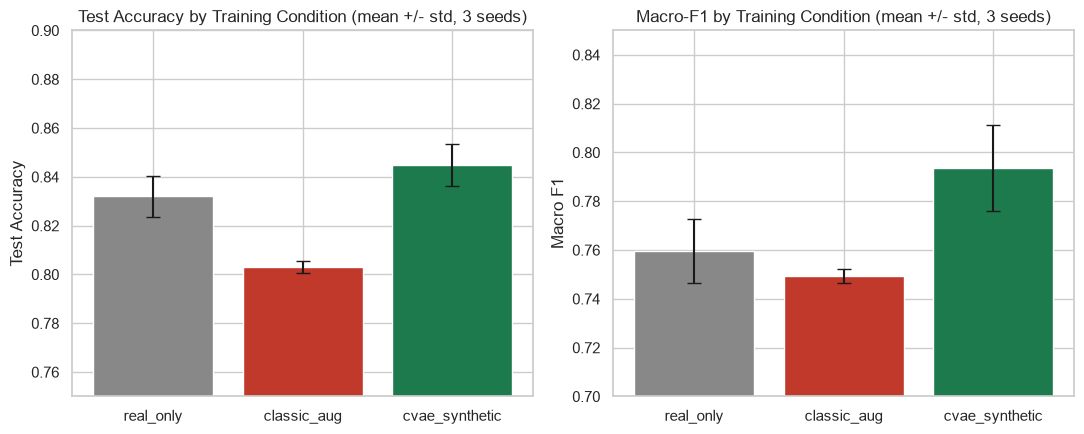

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
arms = list(ablation.keys())
colors = ["#888888", "#c0392b", "#1d7a4c"]

axes[0].bar(arms, [ablation[a]["test_acc_mean"] for a in arms],
            yerr=[ablation[a]["test_acc_std"] for a in arms], color=colors, capsize=5)
axes[0].set_ylabel("Test Accuracy")
axes[0].set_title("Test Accuracy by Training Condition (mean +/- std, 3 seeds)")
axes[0].set_ylim(0.75, 0.90)

axes[1].bar(arms, [ablation[a]["macro_f1_mean"] for a in arms],
            yerr=[ablation[a]["macro_f1_std"] for a in arms], color=colors, capsize=5)
axes[1].set_ylabel("Macro F1")
axes[1].set_title("Macro-F1 by Training Condition (mean +/- std, 3 seeds)")
axes[1].set_ylim(0.70, 0.85)

plt.tight_layout()
plt.savefig("figure2_ablation_results.png", dpi=150)
plt.show()


`cvae_synthetic` outperforms both `real_only` and `classic_aug` on both metrics, and the macro-F1
gain is proportionally larger than the accuracy gain, consistent with the synthetic augmentation
being concentrated on rare classes that weigh more heavily in macro-F1 than in overall accuracy.
`classic_aug` actually underperforms the plain baseline here. The
`cvae_synthetic` seed-42 model is selected as the integrated system's classifier for Stage C.


## 5. Stage C - Agentic Safety Evaluation (P6)

P6's `SafetyAgent` (deterministic safeguards + Claude reasoning + session memory) is reused
without modification, wrapping two classifiers: `real_only` (baseline) and `cvae_synthetic`
(Stage B's best arm). This tests whether synthetic augmentation changes the *integrated* system's
behavior, not just the bare classifier's accuracy.

A small number of live cases are run inline below so the mechanism is reproducible in this
notebook. The full evaluation (10 cases/class, 430 cases per classifier, 860 live Claude calls
total) was run once via `04_agent_eval.py`, since reissuing hundreds of live API calls on every
notebook execution is unnecessary cost; its results are loaded and visualized here.


In [7]:
_, hf_test_raw = load_gtsrb()
demo_indices = [0, 1, 2]

for arm, ckpt in [("real_only", "checkpoints/real_only_seed42.pt"),
                   ("cvae_synthetic", "checkpoints/cvae_synthetic_seed42.pt")]:
    print(f"=== {arm} (live demo, {len(demo_indices)} cases) ===")
    clf = ClassifierTool(ckpt, CLASS_NAMES)
    agent = SafetyAgent(clf, memory=SessionMemory())
    for idx in demo_indices:
        row = hf_test_raw[idx]
        entry = agent.review(row["image"], case_id=f"demo_{arm}_{idx}", true_label=CLASS_NAMES[row["label"]])
        print(f"  true={entry['true_label']:<30} pred={entry['classifier_output']['predicted_class']:<30} "
              f"decision={entry['final_decision']:<9} overridden={entry['llm_overridden']}")
    print()


=== real_only (live demo, 3 cases) ===


  true=Speed limit (20km/h)           pred=Speed limit (30km/h)           decision=ACCEPT    overridden=False


  true=Speed limit (20km/h)           pred=Speed limit (30km/h)           decision=ACCEPT    overridden=False


  true=Speed limit (20km/h)           pred=Speed limit (30km/h)           decision=ACCEPT    overridden=False

=== cvae_synthetic (live demo, 3 cases) ===


  true=Speed limit (20km/h)           pred=Speed limit (20km/h)           decision=ESCALATE  overridden=False


  true=Speed limit (20km/h)           pred=Speed limit (30km/h)           decision=ESCALATE  overridden=False


  true=Speed limit (20km/h)           pred=Speed limit (20km/h)           decision=ESCALATE  overridden=False



In [8]:
with open("agent_eval_results.json") as f:
    agent_eval = json.load(f)

summary_rows = []
for arm, data in agent_eval.items():
    summary_rows.append({"arm": arm, **data["summary"]})
agent_summary_df = pd.DataFrame(summary_rows).set_index("arm")
agent_summary_df


,n_total,n_accept,n_escalate,accept_rate,accept_accuracy,n_accept_incorrect,n_safety_critical_misses_accepted,llm_overridden_count
arm,,,,,,,,
real_only,430,295,135,0.686047,0.891525,32,5,0
cvae_synthetic,430,284,146,0.660465,0.919014,23,5,0


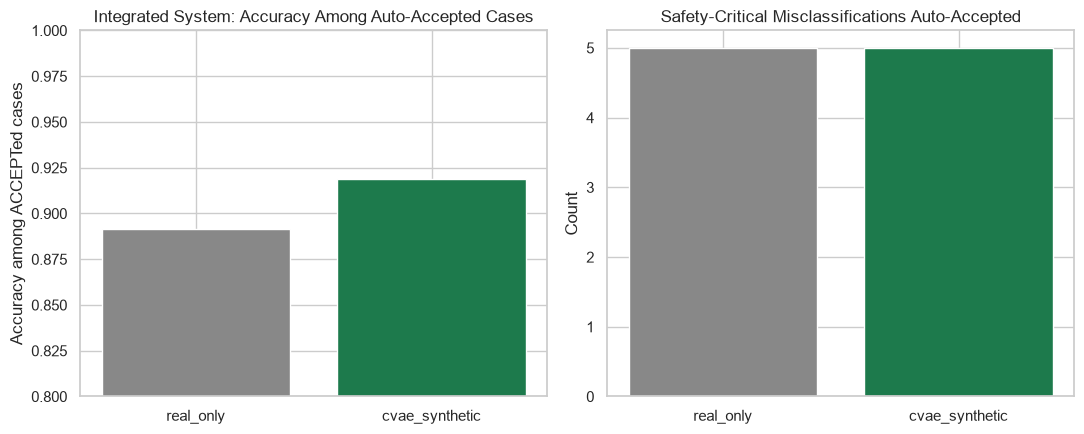

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
arms = list(agent_eval.keys())
colors = ["#888888", "#1d7a4c"]

axes[0].bar(arms, [agent_eval[a]["summary"]["accept_accuracy"] for a in arms], color=colors)
axes[0].set_ylabel("Accuracy among ACCEPTed cases")
axes[0].set_title("Integrated System: Accuracy Among Auto-Accepted Cases")
axes[0].set_ylim(0.80, 1.0)

axes[1].bar(arms, [agent_eval[a]["summary"]["n_safety_critical_misses_accepted"] for a in arms], color=colors)
axes[1].set_ylabel("Count")
axes[1].set_title("Safety-Critical Misclassifications Auto-Accepted")

plt.tight_layout()
plt.savefig("figure3_agent_eval.png", dpi=150)
plt.show()


## 6. Failure Case

Even the best classifier in this pipeline can be confidently wrong in a way the deterministic
safeguards do not catch, because the safeguards key off the *predicted* class and its confidence,
not the true class. A concrete example from the live demo above: a `Speed limit (20km/h)` sign
confidently (and incorrectly) classified as `Speed limit (30km/h)` with a large top-1/top-2 margin
is auto-ACCEPTed, since nothing about that specific confident, unambiguous (but wrong) prediction
trips any threshold. This is the same class of failure Project 6 documented for the original
classifier; it persists in the Stage B `cvae_synthetic` classifier too, because the safeguards
themselves were not changed, only the classifier's training data was. Any system design that wires
a confidence-based escalation agent to a classifier should treat this as a known, structural
limitation, not an edge case that more training data alone will remove.


## 7. Summary

| Stage | Reuses | New in this project |
|---|---|---|
| A | Project 5's VAE architecture | Class-conditioning on GTSRB labels |
| B | Project 4's CNN architecture | 3-condition x 3-seed controlled ablation |
| C | Project 6's SafetyAgent (unmodified) | Evaluated against two different upstream classifiers |

The integrated pipeline shows a real, measured benefit from combining the three components:
targeted synthetic augmentation (Stage A) improves the classifier Stage C's agent wraps (Stage B),
and the full evaluation in Stage C confirms that improvement is still visible once the safety
agent is in the loop, not just at the bare classifier level. See `module_summary.pdf` for the full
reflective analysis, ethical considerations, and references.
